<a href="https://colab.research.google.com/github/sjlee53/ESAA-submission/blob/YB/YB_1127_%EC%97%B0%EC%8A%B5%EB%AC%B8%EC%A0%9C_%EC%B0%A8%EC%9B%90%EC%B6%95%EC%86%8C.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# 데이터 로드
from sklearn.datasets import fetch_openml
mnist=fetch_openml('mnist_784', version=1)

In [2]:
# train, test split
X_train = mnist['data'][:60000]
y_train = mnist['target'][:60000]
X_test = mnist['data'][60000:]
y_test = mnist['target'][60000:]

* 랜덤포레스트에 적용

In [3]:
# 랜덤포레스트에 적용 (n_estimators=10, random_state=42)
import time
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=10, random_state=42)

start = time.time()
rf.fit(X_train, y_train)
fit_time_origin = time.time() - start
print('원본 데이터 훈련 시간: {:.1f}초'.format(fit_time_origin))   # 3.7초


원본 데이터 훈련 시간: 9.7초


In [4]:
# 정확도 결과
from sklearn.metrics import accuracy_score

pred = rf.predict(X_test)
acc_origin = accuracy_score(y_test, pred)
print('원본 데이터 정확도: {:.4f}'.format(acc_origin))   # 0.9492

원본 데이터 정확도: 0.9492


# 1. PCA

* PCA로 변환한 데이터 세트에 랜덤 포레스트 적용

In [5]:
# PCA 라이브러리 불러오기
from sklearn.decomposition import PCA

In [6]:
# PCA 적용 95% : n_components=0.95
pca = PCA(n_components=0.95)
X_train_pca = pca.fit_transform(X_train)

print('784개 -> {}개로 축소'.format(X_train_pca.shape[1]))        # 154개
print('보존된 분산: {:.4f}'.format(pca.explained_variance_ratio_.sum()))   # 0.9502

784개 -> 154개로 축소
보존된 분산: 0.9502


In [7]:
# PCA 이후 랜덤포레스트 훈련
rf_pca = RandomForestClassifier(n_estimators=10, random_state=42)

start = time.time()
rf_pca.fit(X_train_pca, y_train)
fit_time_pca = time.time() - start
print('PCA 변환 데이터 훈련 시간: {:.1f}초'.format(fit_time_pca))   # 11.0초

PCA 변환 데이터 훈련 시간: 26.2초


In [8]:
# 정확도 결과 (X_test도 PCA 적용해야합니다.)
# test 에는 fit_transform 이 아니라 transform 만 쓴다
X_test_pca = pca.transform(X_test)

pred_pca = rf_pca.predict(X_test_pca)
acc_pca = accuracy_score(y_test, pred_pca)
print('PCA 변환 데이터 정확도: {:.4f}'.format(acc_pca))   # 0.8925

PCA 변환 데이터 정확도: 0.8925


**관련 문제**

* PCA모델을 와인 데이터셋에 적용하여 차원을 축소하고 그 결과를 그래프로 나타내보세요.

(1) 필요한 모듈 불러오기

In [9]:
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

(2)  load_wine을 사용해 데이터셋을 생성한다.

In [10]:
wine = load_wine()
X = wine.data
y = wine.target
print('데이터 크기:', X.shape)   # (178, 13)

데이터 크기: (178, 13)


(3) X에 표준 스케일링(Standard scaling)을 적용하여 X_scaled을 생성한다.

In [11]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

(4) PCA 모델을 X에 적용하여 2개의 차원으로 추출한다. 단, random_state=1234로 설정한다.

In [12]:
#PCA 모델을 X_scaled에 적용하여 2개의 차원으로 추출한다.
pca = PCA(n_components=2, random_state=1234)
X_pca = pca.fit_transform(X_scaled)

print('변환 후 크기:', X_pca.shape)
print('분산 비율:', pca.explained_variance_ratio_.round(4))   # [0.362  0.1921]

변환 후 크기: (178, 2)
분산 비율: [0.362  0.1921]


(5) 추출한 피처를 그래프로 나타내라.

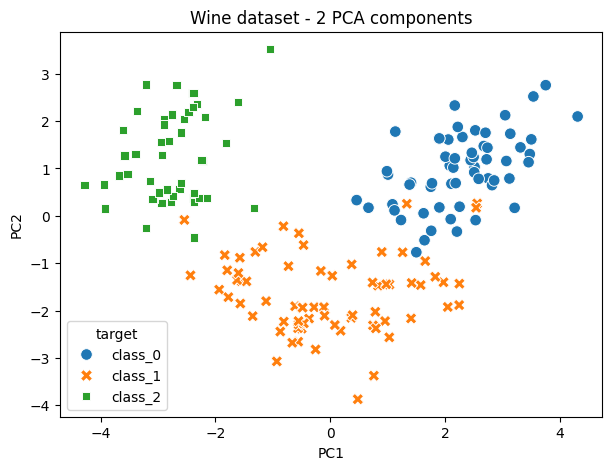

In [13]:
pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
pca_df['target'] = [wine.target_names[i] for i in y]

plt.figure(figsize=(7, 5))
sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='target', style='target', s=70)
plt.title('Wine dataset - 2 PCA components')
plt.show()

# 2. LDA

- LDA로 변환한 데이터 세트에 랜덤 포레스트 적용

In [14]:
# LDA 라이브러리 불러오기
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

In [15]:
# LDA 적용 : n_components=5
# LDA 는 정답을 쓰는 지도 방식이라 fit 에 y_train 을 같이 넣는다
lda = LinearDiscriminantAnalysis(n_components=5)
X_train_lda = lda.fit_transform(X_train, y_train)

print('784개 -> {}개로 축소'.format(X_train_lda.shape[1]))

784개 -> 5개로 축소


In [16]:
# LDA 이후 랜덤포레스트 훈련
rf_lda = RandomForestClassifier(n_estimators=10, random_state=42)

start = time.time()
rf_lda.fit(X_train_lda, y_train)
fit_time_lda = time.time() - start
print('LDA 변환 데이터 훈련 시간: {:.1f}초'.format(fit_time_lda))   # 2.4초

LDA 변환 데이터 훈련 시간: 3.2초


In [17]:
# 정확도 결과 (X_test도 LDA 적용해야합니다.)
X_test_lda = lda.transform(X_test)   # y_test 는 넣지 않는다

pred_lda = rf_lda.predict(X_test_lda)
acc_lda = accuracy_score(y_test, pred_lda)
print('LDA 변환 데이터 정확도: {:.4f}'.format(acc_lda))   # 0.8301

LDA 변환 데이터 정확도: 0.8301
